In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

import opendata_bcn as bcn

income = bcn.download_income(2023)        # disposable income per person (EUR), 2023
pop = bcn.download_population(2024)       # population on 1 January 2024
age = bcn.download_population_age(2024)   # population aged 75+ and 0-4
sections = bcn.download_sections()        # census section polygons
shelters = bcn.download_shelters()        # climate shelters (points)
heat = bcn.download_heat_vulnerability()  # global heat vulnerability score (2015 study)

sec = (sections.merge(income[["section_id", "income_eur"]], on="section_id", validate="one_to_one")
               .merge(pop, on="section_id", validate="one_to_one")
               .merge(age, on="section_id", how="left", validate="one_to_one"))
sec["pop_75plus"] = sec["pop_75plus"].fillna(0)

# heat vulnerability: the study uses slightly older polygons, so take the value of the polygon
# that contains one point of each current section
points = sec[["section_id", "geometry"]].copy()
points["geometry"] = sec.geometry.representative_point()
joined = gpd.sjoin(points, heat, predicate="within", how="left").drop_duplicates("section_id")
sec["vuln_total"] = sec["section_id"].map(joined.set_index("section_id")["vuln_total"])

print(len(sections), len(sec), int(sec["population"].sum()), sec.crs)
print(len(shelters), "shelters |", int(shelters.geometry.is_empty.sum()), "empty geometries")
print("area of the sections (km2):", round(sec.area.sum() / 1e6, 1))
print("aged 75+: %.1f %% of the population" % (100 * sec["pop_75plus"].sum() / sec["population"].sum()))
print("heat vulnerability matched for", int(sec["vuln_total"].notna().sum()), "of", len(sec), "sections")


1068 1068 1702814 EPSG:25831
564 shelters | 0 empty geometries
area of the sections (km2): 101.7
aged 75+: 11.1 % of the population
heat vulnerability matched for 1068 of 1068 sections


In [2]:
def weighted_decile(income, weight):
    # decile of each section, with about 10 % of the population in each decile
    order = np.argsort(income.to_numpy())
    w = weight.to_numpy()[order]
    mid = (np.cumsum(w) - w / 2) / w.sum()
    dec = np.empty(len(income), dtype=int)
    dec[order] = np.minimum((mid * 10).astype(int) + 1, 10)
    return dec


sec["decile"] = weighted_decile(sec["income_eur"], sec["population"])
print(sec.groupby("decile").agg(sections=("section_id", "count"),
                                 population=("population", "sum"),
                                 income_min=("income_eur", "min"),
                                 income_max=("income_eur", "max"),
                                 vulnerability=("vuln_total", "mean")).round(1).to_string())


        sections  population  income_min  income_max  vulnerability
decile                                                             
1             87      170209       11097       17508            7.2
2            106      170751       17538       20082            6.4
3            111      170136       20106       22015            5.7
4            105      169987       22046       23425            5.5
5            105      171007       23436       24609            5.2
6            113      169856       24615       26176            5.1
7            108      169315       26178       27675            5.2
8            111      170566       27702       30325            5.0
9            111      170688       30355       36005            5.2
10           111      170299       36227       54089            5.0


In [3]:
# Coverage: share of each section's area within a distance of the nearest shelter
# (straight line in a metric projection; population assumed uniform inside a section)
for radius in (400, 800):
    zone = shelters.buffer(radius).union_all()
    share = sec.geometry.intersection(zone).area / sec.geometry.area
    sec[f"pop_{radius}"] = sec["population"] * share
    sec[f"old_{radius}"] = sec["pop_75plus"] * share

# second, rougher measure: distance from one point of each section to the nearest shelter
sec["dist_m"] = sec.geometry.representative_point().apply(lambda p: shelters.distance(p).min())

# shelters inside each section
inside = gpd.sjoin(shelters[["geometry"]], sec[["section_id", "geometry"]], predicate="within")
sec["n_shelters"] = sec["section_id"].map(inside.groupby("section_id").size()).fillna(0)
sec["area_km2"] = sec.area / 1e6


def coverage(group):
    agg = sec.groupby(group, observed=True).agg(
        population=("population", "sum"), pop_75plus=("pop_75plus", "sum"),
        pop_400=("pop_400", "sum"), pop_800=("pop_800", "sum"),
        old_400=("old_400", "sum"), old_800=("old_800", "sum"),
        shelters=("n_shelters", "sum"), area_km2=("area_km2", "sum"),
        median_income=("income_eur", "median"), vulnerability=("vuln_total", "mean"))
    for r in (400, 800):
        agg[f"pct_{r}"] = 100 * agg[f"pop_{r}"] / agg["population"]
        agg[f"pct_old_{r}"] = 100 * agg[f"old_{r}"] / agg["pop_75plus"]
    agg["shelters_per_km2"] = agg["shelters"] / agg["area_km2"]
    agg["shelters_per_10k"] = 10000 * agg["shelters"] / agg["population"]
    return agg


by = coverage("decile")
sec["vuln_group"] = pd.cut(sec["vuln_total"], [0, 4, 6, 9],
                           labels=["low (2-4)", "medium (5-6)", "high (7-9)"])
byv = coverage("vuln_group")
cols = ["median_income", "pct_400", "pct_old_400", "pct_800", "pct_old_800", "shelters_per_km2"]
print(by[cols].round(1).to_string())
print(byv[["population", "median_income", "pct_400", "pct_old_400", "pct_800", "shelters_per_km2",
           "shelters_per_10k"]].round(1).to_string())
print("city: all within 400 m %.1f %%, 800 m %.1f %% | aged 75+: 400 m %.1f %%, 800 m %.1f %%" % (
    100 * sec["pop_400"].sum() / sec["population"].sum(),
    100 * sec["pop_800"].sum() / sec["population"].sum(),
    100 * sec["old_400"].sum() / sec["pop_75plus"].sum(),
    100 * sec["old_800"].sum() / sec["pop_75plus"].sum()))
print("shelters counted in sections:", int(sec["n_shelters"].sum()), "of", len(shelters))
print("Spearman income vs distance:", round(sec["income_eur"].corr(sec["dist_m"], method="spearman"), 2))
print("Spearman income vs vulnerability:",
      round(sec["income_eur"].corr(sec["vuln_total"], method="spearman"), 2))


        median_income  pct_400  pct_old_400  pct_800  pct_old_800  shelters_per_km2
decile                                                                             
1             15721.0     97.1         97.3    100.0        100.0               7.4
2             19064.0     97.1         97.5     99.0         99.5               2.6
3             21067.0     96.1         96.7     99.0         99.1               4.3
4             22864.0     99.7         99.7    100.0        100.0              10.1
5             24068.0     97.7         98.1     99.8         99.8               9.1
6             25538.0     98.2         98.4     98.9         99.2               5.5
7             27000.5     97.7         98.6    100.0        100.0               8.7
8             28707.0     98.2         98.6    100.0        100.0               9.4
9             33067.0     95.8         96.5    100.0        100.0               8.5
10            41802.0     88.3         87.5     98.6         98.4           

Spearman income vs distance: 0.07
Spearman income vs vulnerability: -0.3


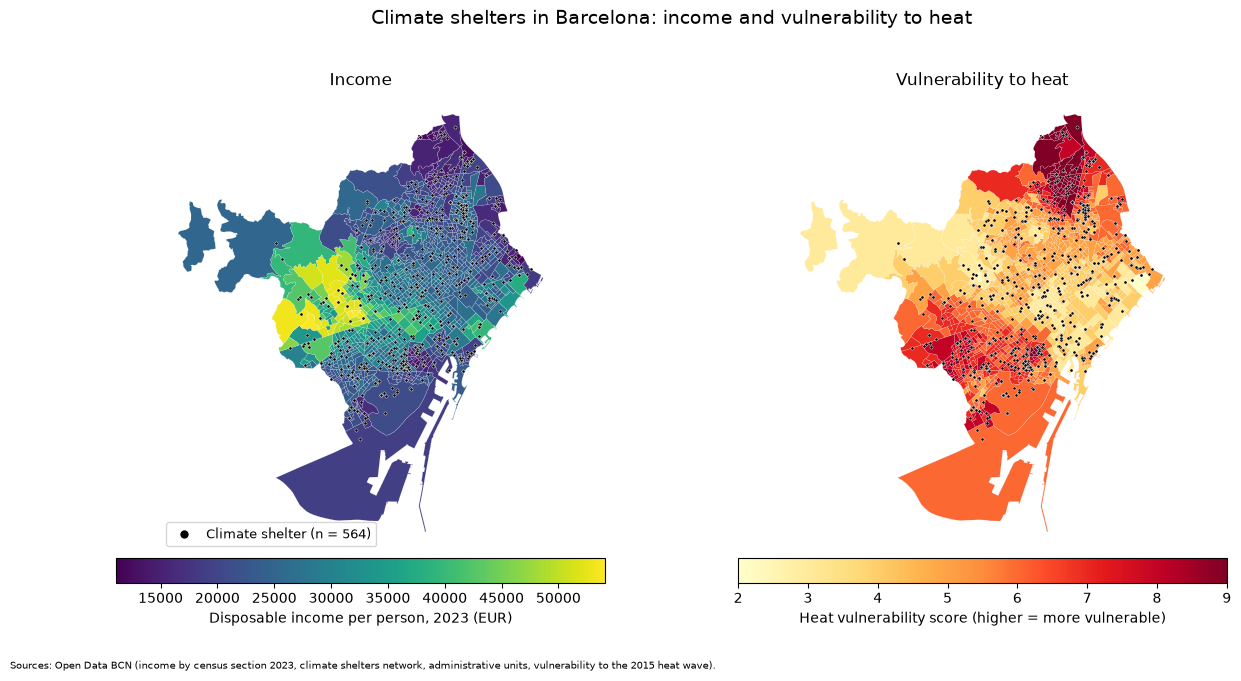

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.8))
panels = [("income_eur", "viridis", "Disposable income per person, 2023 (EUR)", "Income"),
          ("vuln_total", "YlOrRd", "Heat vulnerability score (higher = more vulnerable)",
           "Vulnerability to heat")]
for ax, (col, cmap, label, title) in zip(axes, panels):
    sec.plot(column=col, cmap=cmap, ax=ax, edgecolor="white", linewidth=0.1, legend=True,
             legend_kwds={"label": label, "orientation": "horizontal", "shrink": 0.7,
                          "pad": 0.01})
    shelters.plot(ax=ax, color="black", markersize=5, edgecolor="white", linewidth=0.3)
    ax.set_axis_off()
    ax.set_title(title, fontsize=12)
axes[0].legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
                               markeredgecolor="white", markersize=7,
                               label=f"Climate shelter (n = {len(shelters)})")],
               loc="lower left", frameon=True, fontsize=9)
fig.suptitle("Climate shelters in Barcelona: income and vulnerability to heat", fontsize=14)
fig.text(0.01, 0.01,
         "Sources: Open Data BCN (income by census section 2023, climate shelters network, "
         "administrative units, vulnerability to the 2015 heat wave).", fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 0.96))

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "idea2_income_shelters_map.png", dpi=200)
fig.savefig(out / "idea2_income_shelters_map.svg")


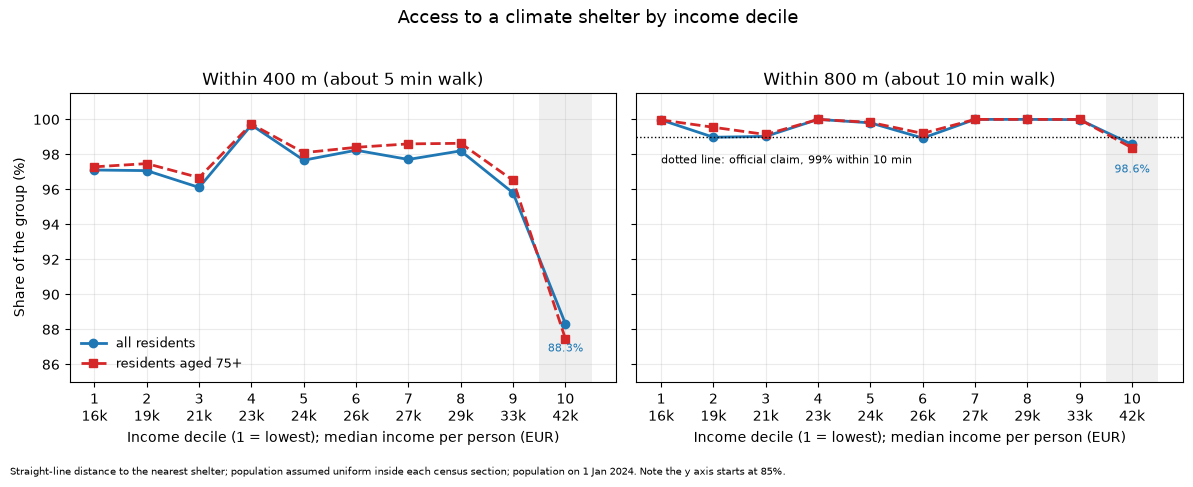

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
x = np.arange(1, 11)
for ax, r, title in ((axes[0], 400, "Within 400 m (about 5 min walk)"),
                     (axes[1], 800, "Within 800 m (about 10 min walk)")):
    ax.plot(x, by[f"pct_{r}"], marker="o", color="tab:blue", lw=2, label="all residents")
    ax.plot(x, by[f"pct_old_{r}"], marker="s", color="tab:red", lw=2, ls="--",
            label="residents aged 75+")
    ax.axvspan(9.5, 10.5, color="grey", alpha=0.12, lw=0)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{d}\n{by.loc[d, 'median_income'] / 1000:.0f}k" for d in x])
    ax.set_xlabel("Income decile (1 = lowest); median income per person (EUR)")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.text(10, by.loc[10, f"pct_{r}"] - 1.6, f"{by.loc[10, f'pct_{r}']:.1f}%", color="tab:blue",
            ha="center", fontsize=8)
axes[1].axhline(99, color="black", ls=":", lw=1)
axes[1].text(1, 98.0, "dotted line: official claim, 99% within 10 min", fontsize=8, va="top")
axes[0].set_ylabel("Share of the group (%)")
axes[0].set_ylim(85, 101.5)
axes[0].legend(loc="lower left", fontsize=9, frameon=False)
fig.suptitle("Access to a climate shelter by income decile", fontsize=13)
fig.text(0.01, 0.01,
         "Straight-line distance to the nearest shelter; population assumed uniform inside each "
         "census section; population on 1 Jan 2024. Note the y axis starts at 85%.",
         fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
fig.savefig(out / "idea2_accessibility_by_income.png", dpi=200)
fig.savefig(out / "idea2_accessibility_by_income.svg")


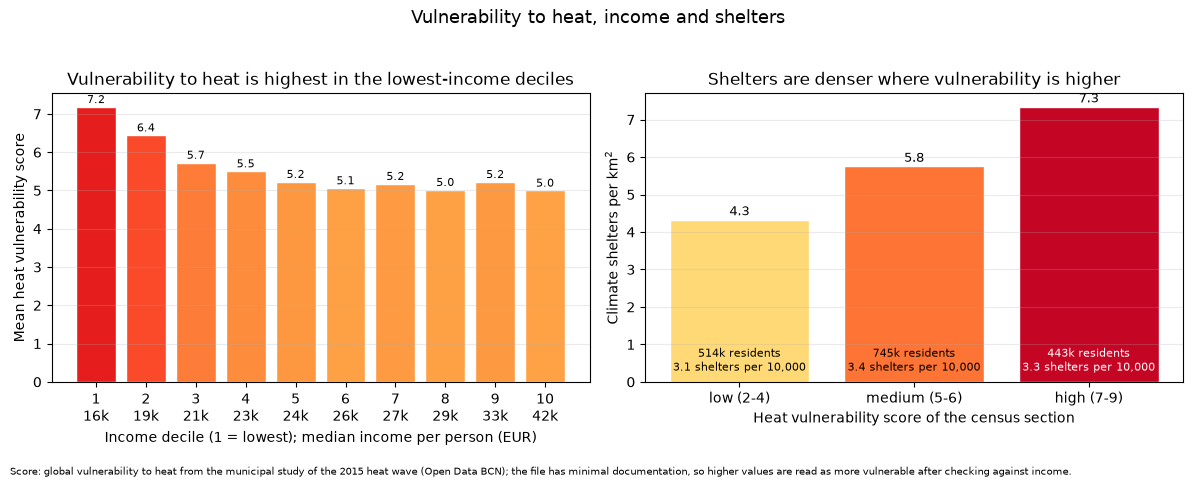

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
x = np.arange(1, 11)
cmap = plt.get_cmap("YlOrRd")
v = by["vulnerability"]
ax1.bar(x, v, color=cmap((v - 2) / 7), edgecolor="white")
for xi, vi in zip(x, v):
    ax1.text(xi, vi + 0.1, f"{vi:.1f}", ha="center", fontsize=8)
ax1.set_xticks(x)
ax1.set_xticklabels([f"{d}\n{by.loc[d, 'median_income'] / 1000:.0f}k" for d in x])
ax1.set_xlabel("Income decile (1 = lowest); median income per person (EUR)")
ax1.set_ylabel("Mean heat vulnerability score")
ax1.set_title("Vulnerability to heat is highest in the lowest-income deciles")
ax1.grid(alpha=0.25, axis="y")

order = list(byv.index)
n = byv["shelters_per_km2"]
ax2.bar(order, n, color=cmap(np.array([0.25, 0.55, 0.85])), edgecolor="white")
for i, (name, val) in enumerate(n.items()):
    ax2.text(i, val + 0.12, f"{val:.1f}", ha="center", fontsize=9)
    ax2.text(i, 0.3, f"{byv.loc[name, 'population'] / 1000:.0f}k residents\n"
                     f"{byv.loc[name, 'shelters_per_10k']:.1f} shelters per 10,000",
             ha="center", fontsize=8, color="white" if i == 2 else "black")
ax2.set_xlabel("Heat vulnerability score of the census section")
ax2.set_ylabel("Climate shelters per km$^2$")
ax2.set_title("Shelters are denser where vulnerability is higher")
ax2.grid(alpha=0.25, axis="y")
fig.suptitle("Vulnerability to heat, income and shelters", fontsize=13)
fig.text(0.01, 0.01,
         "Score: global vulnerability to heat from the municipal study of the 2015 heat wave "
         "(Open Data BCN); the file has minimal documentation, so higher values are read as more "
         "vulnerable after checking against income.", fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
fig.savefig(out / "idea2_heat_vulnerability_by_income.png", dpi=200)
fig.savefig(out / "idea2_heat_vulnerability_by_income.svg")
